# Part 1: Dataset, DDPM architecture and training

In [1]:
import math
import json
import copy
import random
import zipfile
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import save_image

# Configuration
seed = 285
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Dataset paths
mac_dir = Path.home() / "Desktop/ECE 285/Homework 3/data"
hub_root = Path.home() / "private"
hub_dir = hub_root / "data"

candidates = [mac_dir, mac_dir / "data", hub_dir, hub_dir / "data"]

data_dir = next(
    (p for p in candidates if len(list(p.glob("*.png"))) > 100),
    None
)

if data_dir is None:
    archive = hub_root / "data.zip"
    assert archive.exists(), "Dataset not found. Upload data.zip first."

    with zipfile.ZipFile(archive) as zf:
        files_to_extract = [
            f for f in zf.namelist()
            if f.startswith("data/") and f.lower().endswith(".png")
        ]
        zf.extractall(hub_root, members=files_to_extract)

    data_dir = hub_dir

# Hyperparameters
image_size = 128
batch_size = 16 if device.type != "cpu" else 4
epochs = 80
learning_rate = 2e-4
T = 400
sampling_steps = 50
ema_decay = 0.995

output_dir = data_dir.parent / "results_hw3"
output_dir.mkdir(parents=True, exist_ok=True)

files = sorted(data_dir.glob("*.png"))
assert len(files) == 5179, f"Expected 5179 images, found {len(files)}"

# Reproducible 80/10/10 train/validation/test split
indices = torch.randperm(
    len(files), generator=torch.Generator().manual_seed(seed)
).tolist()

n_train = int(0.8 * len(files))
n_val_end = int(0.9 * len(files))

train_files = [files[i] for i in indices[:n_train]]
val_files = [files[i] for i in indices[n_train:n_val_end]]
test_files = [files[i] for i in indices[n_val_end:]]

class HistologyDataset(Dataset):
    def __init__(self, paths, augment=False):
        self.paths = paths
        steps = [transforms.Resize((image_size, image_size))]

        if augment:
            steps += [
                transforms.RandomHorizontalFlip(),
                transforms.RandomVerticalFlip()
            ]

        steps += [
            transforms.ToTensor(),
            transforms.Normalize((0.5,) * 3, (0.5,) * 3)
        ]
        self.transform = transforms.Compose(steps)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as img:
            x = self.transform(img.convert("RGB"))
        return x

train_dataset = HistologyDataset(train_files, augment=True)
val_dataset = HistologyDataset(val_files)
test_dataset = HistologyDataset(test_files)

workers = 2 if device.type == "cuda" else 0

train_loader = DataLoader(
    train_dataset, batch_size=batch_size,
    shuffle=True, num_workers=workers,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size,
    shuffle=False, num_workers=workers
)

test_loader = DataLoader(
    test_dataset, batch_size=16,
    shuffle=False, num_workers=workers
)

print("Device:", device)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Device: mps
Training: 4143
Validation: 518
Testing: 518


In [2]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=64):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        freq = torch.exp(
            -math.log(10000) *
            torch.arange(half, device=t.device) / (half - 1)
        )
        emb = t.float()[:, None] * freq[None]
        return torch.cat([emb.sin(), emb.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.time_fc = nn.Linear(256, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = (
            nn.Conv2d(in_ch, out_ch, 1)
            if in_ch != out_ch else nn.Identity()
        )

    def forward(self, x, t):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_fc(t)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class AttentionBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(
            b, 3, c, h * w
        ).unbind(1)

        weights = (
            (q.transpose(1, 2) @ k) / math.sqrt(c)
        ).softmax(dim=-1)

        out = (v @ weights.transpose(1, 2)).reshape(b, c, h, w)
        return x + self.proj(out)


class NoiseUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.time_mlp = nn.Sequential(
            TimeEmbedding(64),
            nn.Linear(64, 256),
            nn.SiLU(),
            nn.Linear(256, 256)
        )

        self.input = nn.Conv2d(3, 64, 3, padding=1)

        self.enc1 = ResBlock(64, 64)
        self.down1 = nn.Conv2d(64, 128, 4, 2, 1)

        self.enc2 = ResBlock(128, 128)
        self.down2 = nn.Conv2d(128, 256, 4, 2, 1)

        self.enc3 = ResBlock(256, 256)
        self.down3 = nn.Conv2d(256, 256, 4, 2, 1)

        self.mid1 = ResBlock(256, 256)
        self.attn = AttentionBlock(256)
        self.mid2 = ResBlock(256, 256)

        self.up3 = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(256, 256, 3, padding=1)
        )
        self.dec3 = ResBlock(512, 256)

        self.up2 = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(256, 128, 3, padding=1)
        )
        self.dec2 = ResBlock(256, 128)

        self.up1 = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(128, 64, 3, padding=1)
        )
        self.dec1 = ResBlock(128, 64)

        self.output = nn.Sequential(
            nn.GroupNorm(8, 64),
            nn.SiLU(),
            nn.Conv2d(64, 3, 3, padding=1)
        )

    def forward(self, x, t):
        te = self.time_mlp(t)

        s1 = self.enc1(self.input(x), te)
        s2 = self.enc2(self.down1(s1), te)
        s3 = self.enc3(self.down2(s2), te)

        h = self.mid1(self.down3(s3), te)
        h = self.mid2(self.attn(h), te)

        h = self.dec3(torch.cat([self.up3(h), s3], dim=1), te)
        h = self.dec2(torch.cat([self.up2(h), s2], dim=1), te)
        h = self.dec1(torch.cat([self.up1(h), s1], dim=1), te)

        return self.output(h)


# Cosine noise schedule
steps = torch.arange(T + 1, dtype=torch.float64)
schedule = torch.cos(
    ((steps / T + 0.008) / 1.008) * math.pi / 2
) ** 2

schedule = schedule / schedule[0]
betas = (1 - schedule[1:] / schedule[:-1]).clamp(
    1e-4, 0.999
).float().to(device)

alpha_bar = torch.cumprod(1 - betas, dim=0)


def add_noise(x, t, noise):
    a = alpha_bar[t][:, None, None, None]
    return a.sqrt() * x + (1 - a).sqrt() * noise


@torch.no_grad()
def sample_ddim(net, n=16, steps=50, sample_seed=285):
    net.eval()

    generator = torch.Generator().manual_seed(sample_seed)
    x = torch.randn(
        n, 3, image_size, image_size, generator=generator
    ).to(device)

    times = torch.linspace(
        T - 1, 0, steps, device=device
    ).long()

    for i, ti in enumerate(times):
        t = torch.full(
            (n,), int(ti), device=device, dtype=torch.long
        )

        pred_noise = net(x, t)
        a = alpha_bar[ti]

        x0 = (
            (x - (1 - a).sqrt() * pred_noise) / a.sqrt()
        ).clamp(-1, 1)

        a_prev = (
            alpha_bar[times[i + 1]]
            if i + 1 < len(times)
            else x.new_tensor(1.0)
        )

        x = (
            a_prev.sqrt() * x0 +
            (1 - a_prev).sqrt() * pred_noise
        )

    return x.clamp(-1, 1)


model = NoiseUNet().to(device)
ema_model = copy.deepcopy(model).eval()
ema_model.requires_grad_(False)

print("Model parameters:", sum(
    p.numel() for p in model.parameters()
))

Model parameters: 9786947


In [3]:
optimizer = torch.optim.AdamW(
    model.parameters(), lr=learning_rate, weight_decay=1e-4
)

latest_path = output_dir / "ddpm_latest.pt"
best_path = output_dir / "ddpm_best.pt"

history = {"train": [], "val": []}
start_epoch = 0
best_val = float("inf")

if latest_path.exists():
    state = torch.load(
        latest_path, map_location=device, weights_only=True
    )

    model.load_state_dict(state["model"])
    ema_model.load_state_dict(state["ema"])
    optimizer.load_state_dict(state["optimizer"])

    history = state["history"]
    start_epoch = state["epoch"]
    best_val = state["best_val"]

    print("Resuming after epoch:", start_epoch)


@torch.no_grad()
def update_ema():
    for p_ema, p in zip(
        ema_model.parameters(), model.parameters()
    ):
        p_ema.lerp_(p, 1 - ema_decay)


for epoch in range(start_epoch, epochs):
    model.train()
    total_loss = 0

    for x in train_loader:
        x = x.to(device)
        t = torch.randint(0, T, (x.size(0),), device=device)
        noise = torch.randn_like(x)

        noisy = add_noise(x, t, noise)
        predicted = model(noisy, t)

        loss = F.mse_loss(predicted, noise)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        update_ema()

        total_loss += loss.item() * x.size(0)

    train_loss = total_loss / len(train_dataset)

    # Fixed random validation noise for comparable losses
    model.eval()
    val_loss = 0
    val_rng = torch.Generator().manual_seed(seed + 100)

    with torch.no_grad():
        for x in val_loader:
            x = x.to(device)
            t = torch.randint(
                0, T, (x.size(0),), generator=val_rng
            ).to(device)

            noise = torch.randn(
                x.shape, generator=val_rng
            ).to(device)

            predicted = model(add_noise(x, t, noise), t)
            val_loss += F.mse_loss(
                predicted, noise
            ).item() * x.size(0)

    val_loss /= len(val_dataset)

    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if val_loss < best_val:
        best_val = val_loss
        torch.save({
            "epoch": epoch + 1,
            "model": model.state_dict(),
            "ema": ema_model.state_dict(),
            "best_val": best_val
        }, best_path)

    torch.save({
        "epoch": epoch + 1,
        "model": model.state_dict(),
        "ema": ema_model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "history": history,
        "best_val": best_val
    }, latest_path)

    with open(output_dir / "training_history.json", "w") as f:
        json.dump(history, f, indent=2)

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_loss:.4f}"
    )

    if (epoch + 1) % 10 == 0:
        samples = sample_ddim(
            ema_model, n=8, steps=sampling_steps,
            sample_seed=seed
        )

        save_image(
            samples,
            output_dir / f"epoch_{epoch+1:02d}.png",
            nrow=4, normalize=True, value_range=(-1, 1)
        )

# Load best validation checkpoint for evaluation
state = torch.load(
    best_path, map_location=device, weights_only=True
)
ema_model.load_state_dict(state["ema"])
ema_model.eval()

print("Training complete.")
print("Best epoch:", state["epoch"])
print("Best validation loss:", round(state["best_val"], 4))

Epoch 01/80 | Train: 0.1279 | Val: 0.0707
Epoch 02/80 | Train: 0.0585 | Val: 0.0599
Epoch 03/80 | Train: 0.0534 | Val: 0.0553
Epoch 04/80 | Train: 0.0478 | Val: 0.0538
Epoch 05/80 | Train: 0.0494 | Val: 0.0545
Epoch 06/80 | Train: 0.0469 | Val: 0.0517
Epoch 07/80 | Train: 0.0471 | Val: 0.0499
Epoch 08/80 | Train: 0.0457 | Val: 0.0504
Epoch 09/80 | Train: 0.0458 | Val: 0.0499
Epoch 10/80 | Train: 0.0458 | Val: 0.0487
Epoch 11/80 | Train: 0.0449 | Val: 0.0475
Epoch 12/80 | Train: 0.0431 | Val: 0.0482
Epoch 13/80 | Train: 0.0455 | Val: 0.0473
Epoch 14/80 | Train: 0.0434 | Val: 0.0465
Epoch 15/80 | Train: 0.0411 | Val: 0.0467
Epoch 16/80 | Train: 0.0423 | Val: 0.0508
Epoch 17/80 | Train: 0.0441 | Val: 0.0466
Epoch 18/80 | Train: 0.0430 | Val: 0.0469
Epoch 19/80 | Train: 0.0423 | Val: 0.0464
Epoch 20/80 | Train: 0.0443 | Val: 0.0461
Epoch 21/80 | Train: 0.0435 | Val: 0.0467
Epoch 22/80 | Train: 0.0381 | Val: 0.0454
Epoch 23/80 | Train: 0.0428 | Val: 0.0458
Epoch 24/80 | Train: 0.0434 | Val:

# Part 2: Training Loss curves

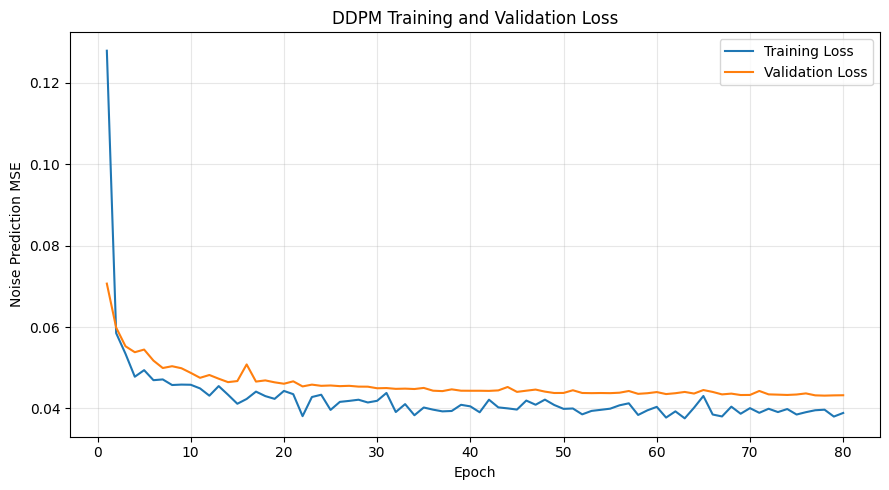

Final training loss: 0.0389
Final validation loss: 0.0432


In [4]:
with open(output_dir / "training_history.json") as f:
    history = json.load(f)

x = range(1, len(history["train"]) + 1)

plt.figure(figsize=(9, 5))
plt.plot(x, history["train"], label="Training Loss")
plt.plot(x, history["val"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Noise Prediction MSE")
plt.title("DDPM Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "training_losses.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Final training loss:", round(history["train"][-1], 4))
print("Final validation loss:", round(history["val"][-1], 4))

# Part 3: FID and Inception score

In [5]:
import json
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from torchvision.models import inception_v3, Inception_V3_Weights
from ignite.metrics import FID

# Load best EMA checkpoint
state = torch.load(
    output_dir / "ddpm_best.pt",
    map_location=device,
    weights_only=True
)

ema_model.load_state_dict(state["ema"])
ema_model.eval()

best_epoch = state["epoch"]
eval_batch_size = 8

print("Selected epoch:", best_epoch)
print("Best validation loss:", state["best_val"])
print("Test images:", len(test_dataset))

eval_loader = DataLoader(
    test_dataset,
    batch_size=eval_batch_size,
    shuffle=False,
    num_workers=workers
)

def prepare_inception(x):
    x = (x.clamp(-1, 1) + 1) / 2

    x = F.interpolate(
        x,
        size=(299, 299),
        mode="bilinear",
        align_corners=False,
        antialias=True
    )

    mean = x.new_tensor(
        [0.485, 0.456, 0.406]
    ).view(1, 3, 1, 1)

    std = x.new_tensor(
        [0.229, 0.224, 0.225]
    ).view(1, 3, 1, 1)

    return (x - mean) / std


cache_path = output_dir / f"eval_features_epoch{best_epoch}.pt"

# Skip expensive generation if features are already saved
if cache_path.exists():
    cached = torch.load(
        cache_path,
        map_location="cpu",
        weights_only=True
    )

    assert cached["sampling_steps"] == sampling_steps
    assert cached["num_images"] == len(test_dataset)

    real_features = cached["real_features"]
    fake_features = cached["fake_features"]
    probabilities = cached["probabilities"]

    print("Loaded cached evaluation features.")

else:
    inception = inception_v3(
        weights=Inception_V3_Weights.IMAGENET1K_V1
    ).to(device).eval()

    classifier = inception.fc
    inception.fc = nn.Identity()

    real_list = []
    fake_list = []
    prob_list = []

    print("Generating and evaluating images...")

    with torch.no_grad():
        for i, real in enumerate(eval_loader):
            real = real.to(device)
            n = real.size(0)

            fake = sample_ddim(
                ema_model,
                n=n,
                steps=sampling_steps,
                sample_seed=seed + 1000 + i
            )

            real_feat = inception(
                prepare_inception(real)
            )

            fake_feat = inception(
                prepare_inception(fake)
            )

            logits = classifier(fake_feat)

            real_list.append(real_feat.cpu())
            fake_list.append(fake_feat.cpu())
            prob_list.append(
                torch.softmax(logits, dim=1).cpu()
            )

            if (i + 1) % 10 == 0:
                processed = min(
                    (i + 1) * eval_batch_size,
                    len(test_dataset)
                )
                print(
                    f"Processed {processed}/{len(test_dataset)} images"
                )

    real_features = torch.cat(real_list)
    fake_features = torch.cat(fake_list)
    probabilities = torch.cat(prob_list)

    torch.save({
        "real_features": real_features,
        "fake_features": fake_features,
        "probabilities": probabilities,
        "sampling_steps": sampling_steps,
        "num_images": len(test_dataset)
    }, cache_path)

    del inception, classifier

    if device.type == "cuda":
        torch.cuda.empty_cache()

    print("Evaluation features saved.")

print("Computing FID...")

fid = FID(
    num_features=2048,
    feature_extractor=nn.Identity(),
    device="cpu"
)

fid.update((fake_features, real_features))
fid_score = float(fid.compute())

p = probabilities.clamp_min(1e-12)
p_mean = p.mean(dim=0).clamp_min(1e-12)

is_score = torch.exp(
    (p * (p.log() - p_mean.log())).sum(dim=1).mean()
).item()

print("\n===== Final Evaluation =====")
print(f"FID: {fid_score:.4f}")
print(f"Inception Score: {is_score:.4f}")

Selected epoch: 78
Best validation loss: 0.043138549465355266
Test images: 518
Generating and evaluating images...
Processed 80/518 images
Processed 160/518 images
Processed 240/518 images
Processed 320/518 images
Processed 400/518 images
Processed 480/518 images
Evaluation features saved.
Computing FID...

===== Final Evaluation =====
FID: 126.8478
Inception Score: 3.4470


In [6]:
with open(output_dir / "training_history.json") as f:
    history = json.load(f)

results = {
    "model": "DDPM with U-Net",
    "dataset": "Histopathology",
    "train_size": len(train_dataset),
    "val_size": len(val_dataset),
    "test_size": len(test_dataset),
    "image_size": image_size,
    "diffusion_steps": T,
    "sampling_steps": sampling_steps,
    "epochs_trained": len(history["train"]),
    "selected_epoch": best_epoch,
    "best_validation_loss": float(state["best_val"]),
    "learning_rate": learning_rate,
    "batch_size": batch_size,
    "fid_2048": fid_score,
    "inception_score": is_score,
    "history": history
}

with open(output_dir / "results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Results saved successfully.")
print("Selected epoch:", best_epoch)
print("FID:", round(fid_score, 4))
print("IS:", round(is_score, 4))

Results saved successfully.
Selected epoch: 78
FID: 126.8478
IS: 3.447


# Part 4: Generated Histopathology image examples

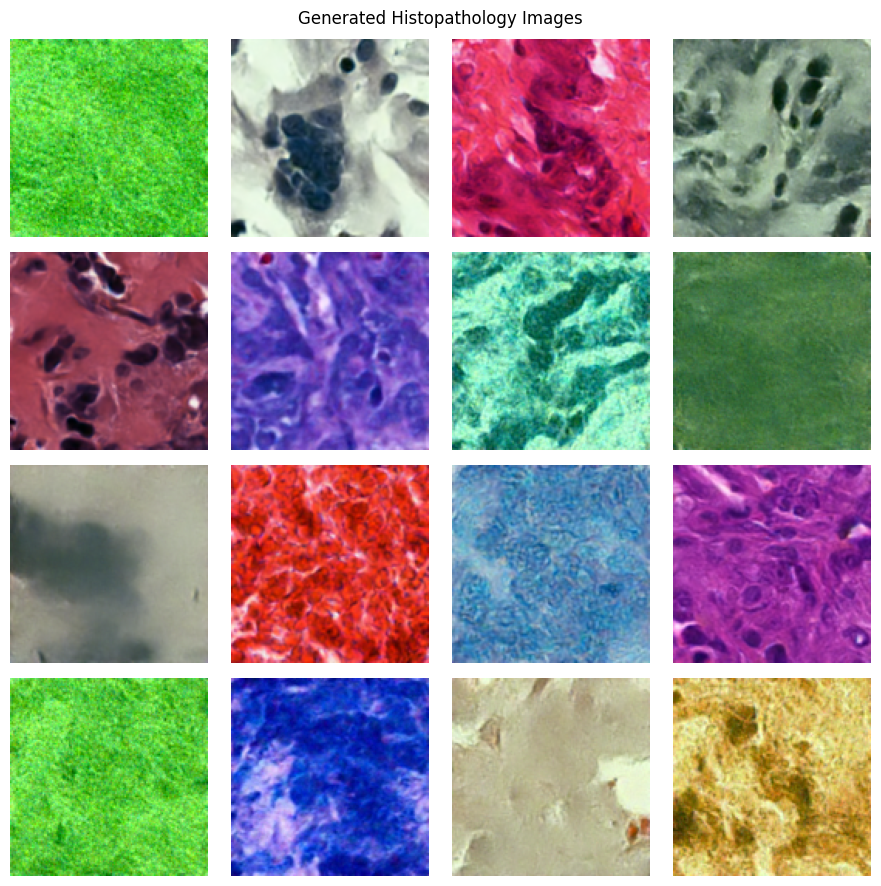

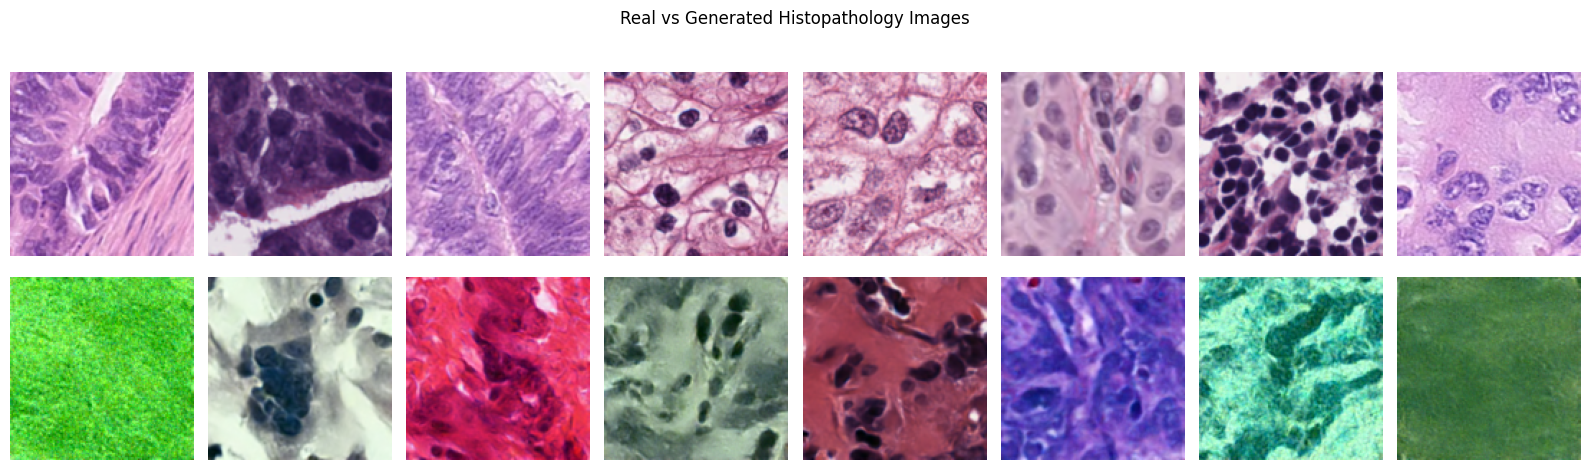

Part 4 completed.
Selected epoch: 78
Figures saved to: /Users/huzichen/Desktop/ECE 285/Homework 3/results_hw3


In [7]:
# Load best EMA model
state = torch.load(
    output_dir / "ddpm_best.pt",
    map_location=device,
    weights_only=True
)

ema_model.load_state_dict(state["ema"])
ema_model.eval()

# Generate 16 images
generated = sample_ddim(
    ema_model,
    n=16,
    steps=sampling_steps,
    sample_seed=seed + 2
).cpu()

generated = (generated + 1) / 2

# Generated image grid
fig, axes = plt.subplots(4, 4, figsize=(9, 9))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated[i].permute(1, 2, 0).clamp(0, 1)
    )
    ax.axis("off")

plt.suptitle("Generated Histopathology Images")
plt.tight_layout()

plt.savefig(
    output_dir / "generated_images.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

save_image(
    generated,
    output_dir / "generated_grid.png",
    nrow=4
)

# Select 8 real test images
rng = torch.Generator().manual_seed(seed)
indices = torch.randperm(
    len(test_dataset), generator=rng
)[:8]

real = torch.stack([
    test_dataset[i.item()] for i in indices
])

real = (real + 1) / 2

# Real vs generated
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):
    axes[0, i].imshow(
        real[i].permute(1, 2, 0).clamp(0, 1)
    )
    axes[1, i].imshow(
        generated[i].permute(1, 2, 0).clamp(0, 1)
    )
    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Real")
axes[1, 0].set_ylabel("Generated")

plt.suptitle("Real vs Generated Histopathology Images")
plt.tight_layout()

plt.savefig(
    output_dir / "real_vs_generated.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

print("Part 4 completed.")
print("Selected epoch:", state["epoch"])
print("Figures saved to:", output_dir)